In [2]:
# depenencies
from astropy.io import fits
import glob
import os
import pandas as pd
import numpy as np
#import 
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
import astropy.units as u
from scipy import stats

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors

#### Making catalog from files to get galaxy name and file for work. Don't run and overwrite custom galaxy catalog stuff if don't need to. Custom galaxy parameters such as x/ycent go directly in .csv.

In [3]:
file_list = glob.glob("../../Data/Capstone/*.fits.fz", recursive=True) # grab file list

modified_names = [filename.replace('../../Data/Capstone/', '').replace('-image-g.fits.fz', '') for filename in file_list] #strip badness so its just name of galaxy

# throw in dataframe for reading into code
catalog = pd.DataFrame({
    'file': file_list,
    'name': modified_names
})
# Display the DataFrame
print(catalog)

# save dataframe
catalog.to_csv("capstone_catalog.csv", index=False)

                                           file      name
0  ../../Data/Capstone/NGC 5633-image-g.fits.fz  NGC 5633


#### Reading in catalog

In [36]:
catalog = pd.read_csv("capstone_catalog.csv")

In [37]:
display(catalog)

,file,name,xcen,ycen,sma,smina,ellip,PA,rlinin,rlinout
0,../../Data/Capstone/NGC 5633-image-g.fits.fz,NGC 5633,2105,387,152,107,0.296053,105,-99,-99


Custom guesses for each galaxy in the catalog are xcen/ycen (center of centroid in pix), sma and smina (semi major and minor axes for ellipse in pix), ellip (the ellipticity), and PA (the physical angle in deg from x direction).

Galaxy name: NGC 5633	Galaxy filepath:../../Data/Capstone/NGC 5633-image-g.fits.fz
152 0.296052631578947


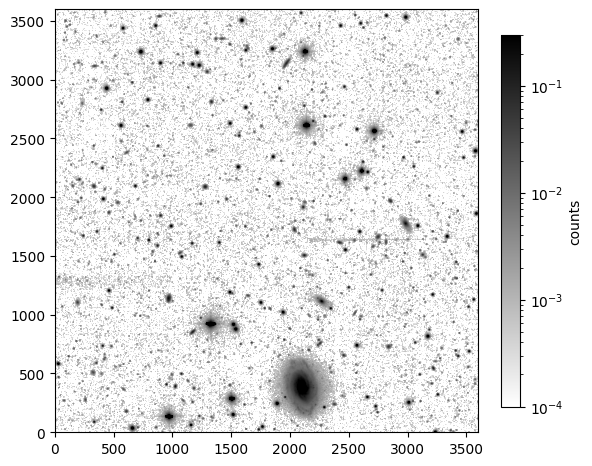

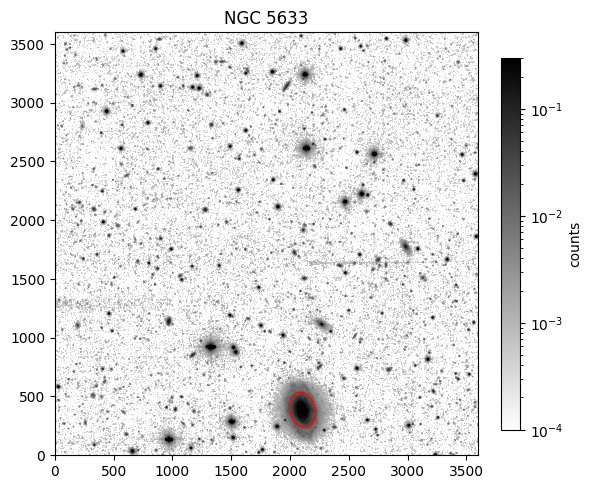

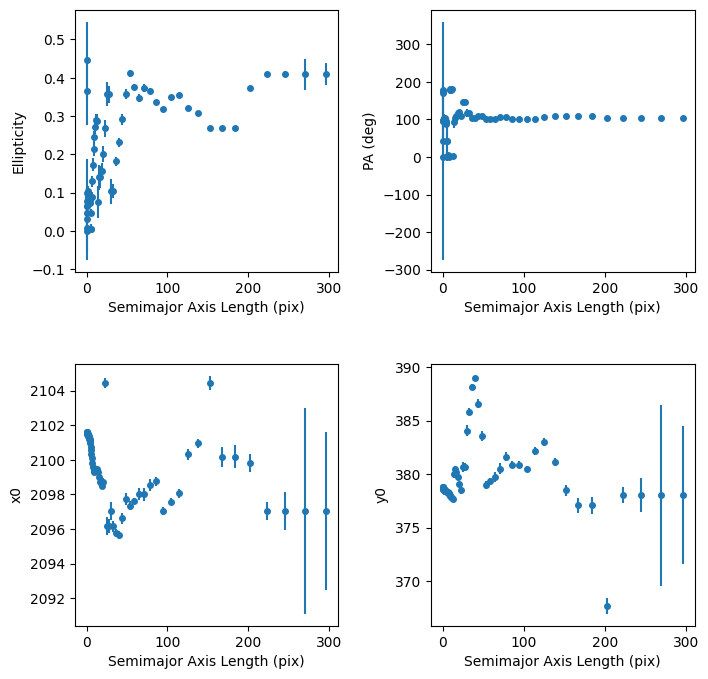

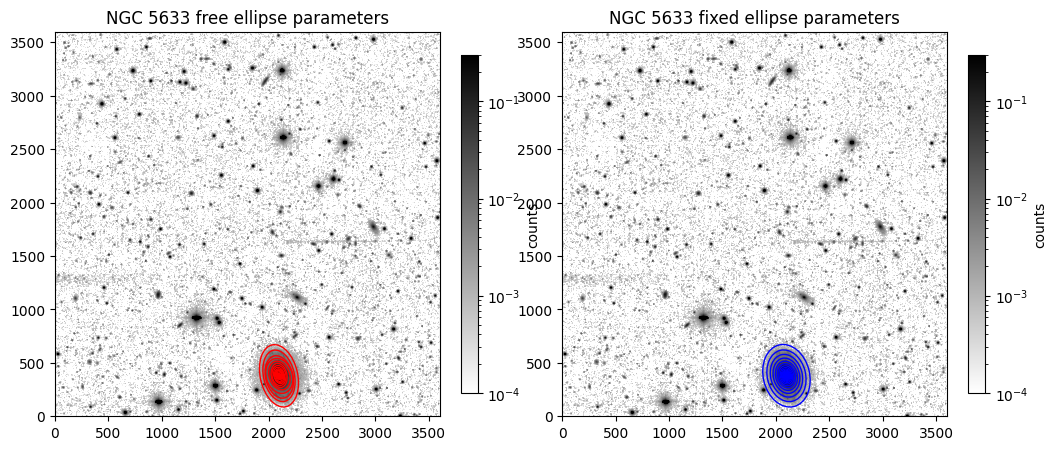

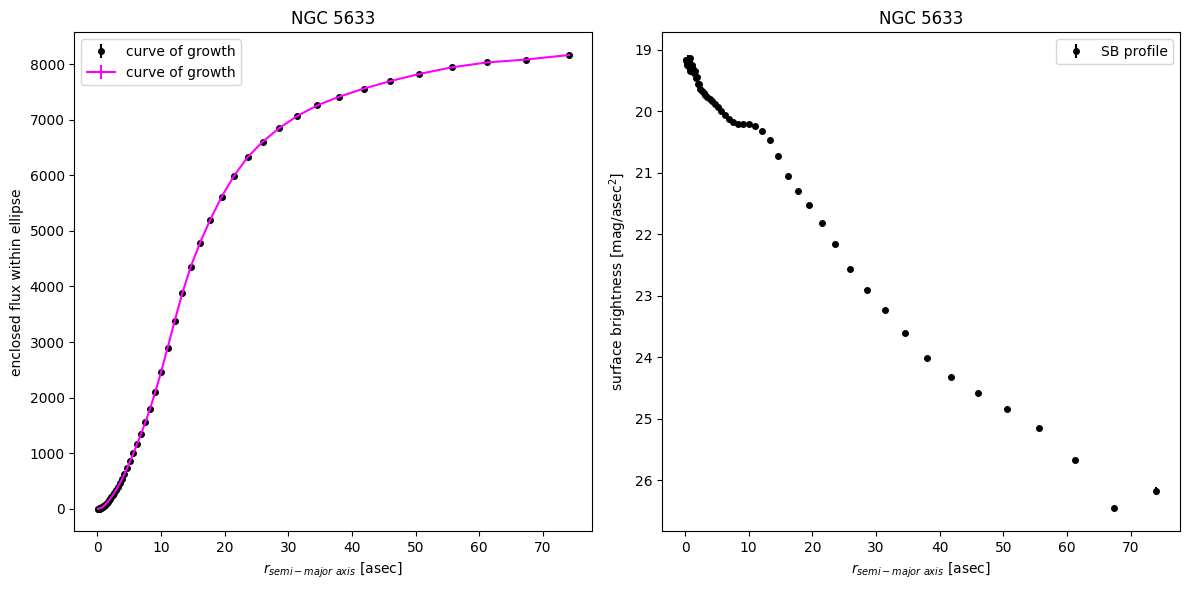

Linear fit:
Central Surface Brightness (μ_0): 19.334 $\pm$ 1.728e-03 mag
Chi2: 66831.99
Reduced Chi2: 1285.23


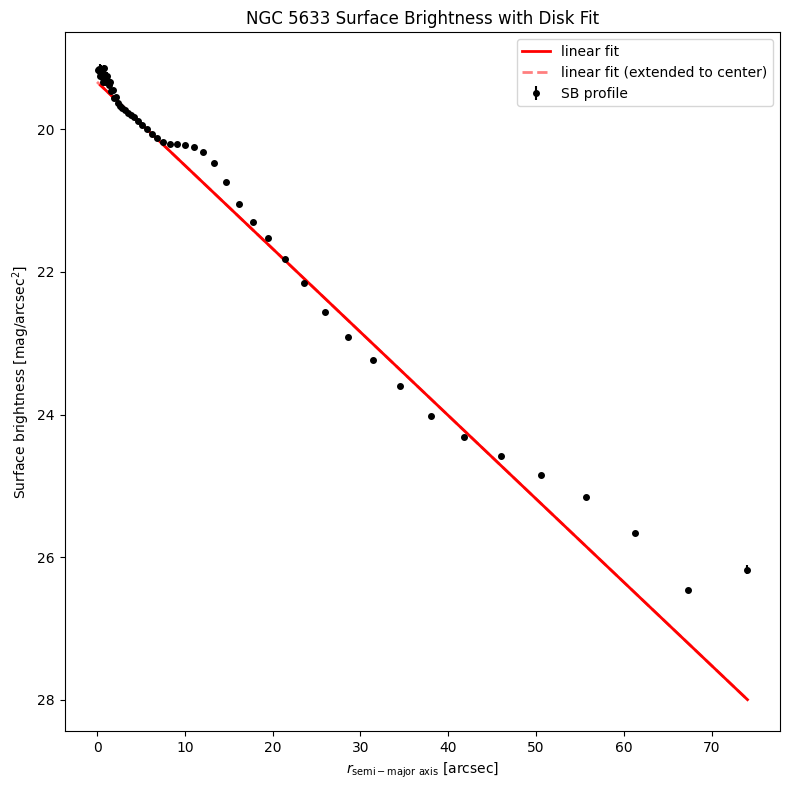

[None]

In [56]:
# Test only the first object
files_to_run = catalog.iloc[[0]]
# Or process everything
# files_to_run = catalog
[ellipsefitting(row, plot_opt = True) for _, row in files_to_run.iterrows()]

#### Helper Functions

In [7]:
def imdisplay(image, v1perc=50, v2perc=99.99, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile

    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    if (logscale):
        #v1 = scoreatpercentile(nimage,v1perc)
        #v2 = scoreatpercentile(nimage,v2perc)
        #print(v1,v2)
        v1 = 0.0001 # debug custom values
        v2 = 0.3 # debug custom values
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        v1 = v1perc
        v2 = v2perc
        print(v1,v2)
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax


In [8]:
def imdisplay2(image, v1perc=50, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    if (logscale):
        # determine the pixel values at the 10th and 95th percentile
        #v1 = scoreatpercentile(nimage,v1perc)
        #v2 = scoreatpercentile(nimage,v2perc)
        # display using imshow
        #
        # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
        # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
        #
        # vmin and vmax set the min and max pixel values that
        # will be mapped to the extremes of the colormap
        #print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
        #plot the two figures side by side
        v1 = 0.0001 # debug custom values
        v2 = 0.3 # debug custom values
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        v1 = v1perc
        v2 = v2perc
        print(v1,v2)
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

In [9]:
## FROM Surface Photometry Lab
# Plots outputs of ellipse fitting
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')

    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 180.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')

    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [10]:
## FROM Surface Photometry Lab
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list, plot_opt, vminperc=50,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    if plot_opt: #if true plot
        fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
        if plot_opt: #if true plot
            #overplot apertures
            aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])

    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
        if plot_opt: #if true plot
            #overplot apertures
            aperiter.plot(ax=ax[1],color='blue')
    if plot_opt: #if true plot
        ax[0].set_title(galname + ' free ellipse parameters')
        ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav

### Full Ellipse Function

In [ ]:
from photutils.isophote import Ellipse
from photutils.isophote import EllipseGeometry
from photutils.aperture import ApertureStats, EllipticalAnnulus, EllipticalAperture
def ellipsefitting(gal, plot_opt, image_hdu=1):
    # TAKE IN:
    # gal : Galaxy row in catalog, with all initial guesses n stuff, also filename for image
    # image_hdu : which hdu is the image in hehe
    # plot_opt : do you want to do plots? True / False
    image = []
    header = []

    print(f'Galaxy name: {gal["name"]}\tGalaxy filepath:{gal["file"]}')
    
    with fits.open(gal["file"]) as hdul:
        # initial file image readin and header readin
        image = hdul[image_hdu].data
        header = hdul[image_hdu].header
        if plot_opt: # If true plot stuff
            # display first image
            imdisplay(image)
            
        # init empty geometry object for ELlipseGeometry
        geometry = {}
        geometry = EllipseGeometry(x0 = gal['xcen'], 
                                      y0 = gal['ycen'],
                                      sma = gal['sma'],
                                      eps = gal['ellip'],
                                      pa = gal['PA'] * np.pi/180)   #convert into radians
        print(geometry.sma,geometry.eps )
        
        #make an aperture to overplot so that we can check if it makes sens
        aper = EllipticalAperture((geometry.x0, geometry.y0), geometry.sma, 
                          geometry.sma * (1.-geometry.eps), geometry.pa)
        
        if plot_opt: # If true plot stuff
            #plot our image
            fig,ax = imdisplay(image,v1perc=50,v2perc=99.99,logscale=True)
            aper.plot(color='red') # plot aperture on top
            plt.title(gal['name'])

        #initialize dictionary for ellipse fitting
        ellipse = {}
        isolist = {}
        xcenav = {}
        ycenav = {}
        epsav = {}
        paav = {}

        # this fits the isophotes using our initial guesses
        ellipse = Ellipse(image, geometry)
        isolist = ellipse.fit_image()

        # output table of every ellipse
        # comment out if needed
        #display(isolist.eps)

        if plot_opt: # If true plot stuff
            #make a set of plots that show some attributes of every ellipse.
            plotellipse(isolist)
        #save the shape values of the average ellipse.  We will need this later for aperture photometry
        xcenav, ycenav, epsav, paav = plotaper(gal['name'], image, isolist, plot_opt) #weird passing on phot_opt plotting option here,, but we will see
        #print(xcenav, ycenav, epsav, paav) # debug print stuff to check it got saved

        # ---------- surface brightness profile ----------
        magzp = header['MAGZERO']
        pixscale = header['CD2_2'] * 3600.   # asec/pix

        rcent = np.array([])
        sbcent = np.array([])
        sbcent_err = np.array([])
        totflux = np.array([])
        totflux_err = np.array([])
        numpix = np.array([])

        a_in = 0.01  # first annulus runs from the center out to the first isophote
        #set up elliptical annulus using parameters at rhalf
        for a_out in isolist.sma[1:]:
            a_in_old = a_in

            b_out = a_out * (1. - epsav)
            b_in = a_in_old * (1. - epsav)

            annulus_aperture = EllipticalAnnulus(
                (xcenav, ycenav), a_in_old, a_out, b_out,
                b_in=b_in, theta=paav
            )
            total_aperture = EllipticalAperture(
                (xcenav, ycenav), a_out, b_out, theta=paav
            )

            stats_ann = ApertureStats(image, annulus_aperture)
            stats_tot = ApertureStats(image, total_aperture)

            numpix = float(np.asarray(stats_ann.sum_aper_area))
            avflux = float(stats_ann.mean)
            stdflux = float(stats_ann.std)

            rcent = np.append(rcent, (a_in_old + a_out) / 2. * pixscale)
            totflux = np.append(totflux, stats_tot.sum)
            totflux_err = np.append(totflux_err, stats_tot.std)  # See note below

            pixarea = pixscale ** 2
            sbcent = np.append(
                sbcent, magzp - 2.5 * np.log10(avflux / pixarea)
            )

            avflux_err = stdflux / np.sqrt(numpix)
            sbcent_err = np.append(
                sbcent_err, (2.5 / np.log(10)) * (avflux_err / avflux)
            )

            a_in = a_out
        if plot_opt:
            # plotting
            fig, ax = plt.subplots(1, 2, figsize=(12, 6))
            ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
                fmt='o', markersize=4, color='black', label='curve of growth')
            ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
                fmt='-', markersize=4, color='magenta', label='curve of growth')
            ax[0].set_xlabel(r"$r_{semi-major~axis}$ [asec]")
            ax[0].set_ylabel("enclosed flux within ellipse")
            ax[0].set_title(gal["name"])
            ax[0].legend()

            ax[1].errorbar(
                rcent, sbcent, yerr=sbcent_err,
                fmt="o", markersize=4, color="black", label="SB profile",
            )
            ax[1].invert_yaxis()
            ax[1].set_xlabel(r"$r_{semi-major~axis}$ [asec]")
            ax[1].set_ylabel(r"surface brightness [mag/asec$^2$]")
            ax[1].set_title(f"{gal['name']}")
            ax[1].legend()

            plt.tight_layout()
            plt.show()

        # linear fitting
        print('Linear fit:')
        if (gal['rlinin'] and gal['rlinout']) != -99: # if bounds for linear fit exist in catalog, bound fit to this
            rlinin = gal['rlinin'] # not to be confused with V. Lenin, linear fit radius, inside, units of arcsec
            rlinout = gal['rlinout'] # outer linear fit radius, arcsec
            print(f'\tInner Radius of fit: {rlinin:.2f}\nOuter Radius of fit: {rlinout:.2f}')
             # Fit only points at and outside the chosen radius.
            fit_good = (
                (rcent >= rlinin)
                & (rcent <= rlinout)
                & (sbcent_err > 0)
            )
            bounds = True
        else:
            fit_good = (sbcent_err > 0) # fit all
            bounds = False

        rfit_data = rcent[fit_good]
        sbfit_data = sbcent[fit_good]
        errfit_data = sbcent_err[fit_good]
        
        (slope, intercept), cov = np.polyfit(
            rfit_data,
            sbfit_data,
            1,
            w=1.0 / errfit_data,
            cov="unscaled",
        )

        model = slope * rfit_data + intercept
        chi2 = np.sum(((sbfit_data - model) / errfit_data) ** 2) # chi2 thx greg
        redchi2 = chi2 / (len(rfit_data) - 2) # reduced chi2 thx greg
        mu0 = intercept
        mu0_err = np.sqrt(cov[1, 1])

        print(f'Central Surface Brightness (μ_0): {mu0:.3f} $\pm$ {mu0_err:.3e} mag')
        print(f'Chi2: {chi2:.2f}')
        print(f'Reduced Chi2: {redchi2:.2f}')

        if plot_opt:
            # plot data
            plt.figure(figsize=(6, 6))
            plt.errorbar(
                rcent, sbcent, yerr=sbcent_err,
                fmt="o", markersize=4, color="black", label="SB profile",
            )
            rline = np.linspace(rfit_data.min(), rfit_data.max(), 100) # model line
            tocentrline = np.linspace(0,rfit_data.max(),100) # model line from minimum to 0
            plt.plot(
                rline, slope * rline + intercept,
                color="red", lw=2, label="linear fit",
            )
            plt.plot(
                tocentrline, slope * tocentrline + intercept, '--',
                color="red", lw=2, alpha = 0.5, label="linear fit (extended to center)",
            )
            if bounds:
                plt.axvline(
                    rlinin, color="gray", ls=":",
                    label=f"fit starts at {rlinin:.2f} arcsec",
                )
                plt.axvline(
                    rlinear_outer, color="gray", ls=":",
                    label=f"fit ends at: {rlinout:.2f} arcsec",
                )
            ax = plt.gca()
            ax.invert_yaxis()
            ax.set_xlabel(r"$r_{\mathrm{semi-major\ axis}}$ [arcsec]")
            ax.set_ylabel(r"Surface brightness [mag/arcsec$^2$]")
            ax.set_title(f"{gal['name']} Surface Brightness with Disk Fit")
            ax.legend()
            plt.tight_layout()
            plt.show()

            

## Background Removal

This section should cover background removal and be optional to the main script. Once we remove background, the script to find isochromes and fit a radial light profile to it should run on the background removed fits' from this section. To reproduce work, do background removal before main work.

In [16]:
#initialize dictionaries that contains names of images and headers, etc. 
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}
bkgmode = {}
bkgmed = {}
data_bsub = {}
imname_busb = {} 


def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

def background_measure(imname,data,header,fig,ax,corners,bkg_size=5):
    fig, ax = imdisplay(data,v1perc=1,v2perc=99,logscale=True)
    plt.title(imname)
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    reg = np.array([])
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])   
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])  
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1]) 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)
    rectlist = []
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed



#A routine to plot the images with the background measurment corners shown in red 
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed


def plotwithredsquare(data,imname,header,bkgdim,fig,ax):
    data[galname], header[galname] = fits.getdata(imname[galname], header=True)
    bkgdim[galname] = 200 
    bkgmode[galname],bkgmed[galname] = bkgregplot(
    data[galname], header[galname], imname[galname], bkgdim[galname], fig, ax)

def bkgsubplot(data,header,imname,fix,ax): 
    data_bsub[galname] = data[galname] - bkgmed[galname] 
    fig,ax = imdisplay(data_bsub[galname],v1perc=40,v2perc=99.9,logscale=True)
    plt.title(galname + ' background reduced')
    imname_busb[galname] = imname[galname].replace("g.fits.fz","g_bsub.fits.fz")
    fits.writeto(imname_busb[galname],data_bsub[galname],overwrite=True,header=header[galname])